# Prueba histórica: ¿el modelo en vivo se adelanta al mercado de Polymarket?

La plataforma en vivo (`streamlit_app.py`, `src/live/`) compara minuto a minuto la probabilidad de un modelo
contra el precio de Polymarket y da señales BUENO / ESPERAR / NO. El equipo pidió que **prediga en vez de
reaccionar**, usando xG en vivo. Este notebook mide, con partidos ya jugados, si eso funciona.

**Diseño** (`src/models/backtest_xg.py`):
- Partidos cerrados de los últimos 21 días con mercado moneyline en Polymarket, emparejados con ESPN.
- Para cada minuto de juego se reconstruye lo que la plataforma habría visto: marcador, xG sin penales
  (`src/live/xg_vivo.py`), rojas, precio de cada resultado y la señal (`src/live/tracker.evaluate`).
- **Sin ventajas injustas:** en cada minuto solo se usa información anterior; los datos de ESPN entran con
  60 s de atraso y la compra se hace al precio del minuto siguiente + 1 pt.
- Métricas: adelanto (¿la diferencia modelo − mercado anticipa el movimiento del precio?), Brier del
  resultado final, señales simuladas y GARCH contra varianza constante.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models import backtest_xg as bt
from src.live import modelo

logging.basicConfig(level=logging.WARNING)
resultados, por_partido = bt.correr(dias=21, max_partidos=80)
print("Partidos:", resultados["partidos"], "| minutos de juego evaluados:", resultados["minutos_evaluados"])
pd.Series(resultados["por_liga"], name="partidos").to_frame().T

Partidos: 80 | minutos de juego evaluados: 7730


,CL,PL,PD,SA,BL1,FL1,DED,PPL,ELC,BSA
partidos,18,18,20,20,4,0,0,0,0,0


## 1. Calibración: error del pronóstico del resultado final (Brier, menor es mejor)

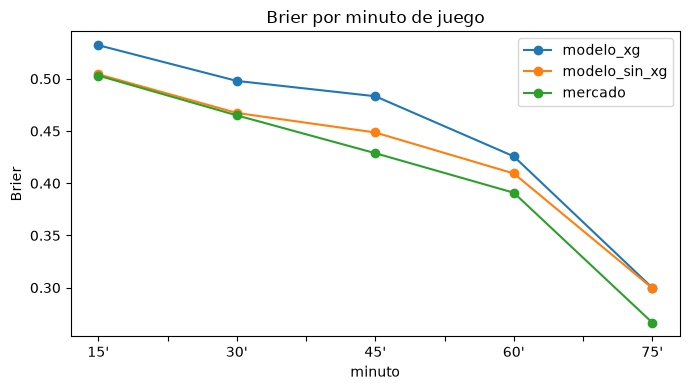

,modelo_xg,modelo_sin_xg,mercado
15',0.532,0.504,0.503
30',0.498,0.467,0.465
45',0.483,0.449,0.429
60',0.426,0.409,0.391
75',0.300,0.300,0.267


In [2]:
brier = pd.DataFrame(resultados["brier"]).T.drop(columns="partidos")
brier.index = [i.replace("min_", "") + "'" for i in brier.index]
ax = brier.plot(marker="o", figsize=(7, 4), title="Brier por minuto de juego")
ax.set_xlabel("minuto"); ax.set_ylabel("Brier")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "backtest_brier_por_minuto.png", dpi=150); plt.show()
brier.round(3)

## 2. Adelanto: ¿la diferencia modelo − mercado anticipa hacia dónde se mueve el precio?

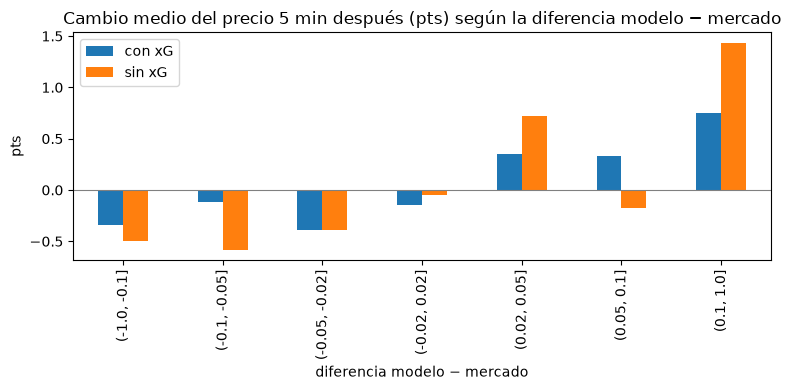

,con_xg,sin_xg
5min,0.018,0.019
10min,0.015,0.016


In [3]:
filas = pd.DataFrame([f for p in por_partido for f in p])
filas["d_xg"] = filas["p_xg"] - filas["mercado"]
filas["d_sin"] = filas["p_sin"] - filas["mercado"]
filas["cambio_5"] = filas["futuro_5"] - filas["mercado"]
bins = [-1, -0.10, -0.05, -0.02, 0.02, 0.05, 0.10, 1]
tabla = pd.DataFrame({
    "con xG": filas.groupby(pd.cut(filas["d_xg"], bins), observed=True)["cambio_5"].mean(),
    "sin xG": filas.groupby(pd.cut(filas["d_sin"], bins), observed=True)["cambio_5"].mean(),
}) * 100
ax = tabla.plot(kind="bar", figsize=(8, 4), title="Cambio medio del precio 5 min después (pts) según la diferencia modelo − mercado")
ax.axhline(0, color="gray", lw=0.8); ax.set_xlabel("diferencia modelo − mercado"); ax.set_ylabel("pts")
plt.tight_layout(); plt.savefig(ROOT / "docs" / "backtest_adelanto.png", dpi=150); plt.show()
pd.DataFrame({k: {h: v["correlacion"] for h, v in d.items()} for k, d in resultados["adelanto"].items()}).round(3)

## 3. Señales BUENO simuladas ($1 por señal, compra al precio del minuto siguiente + 1 pt)

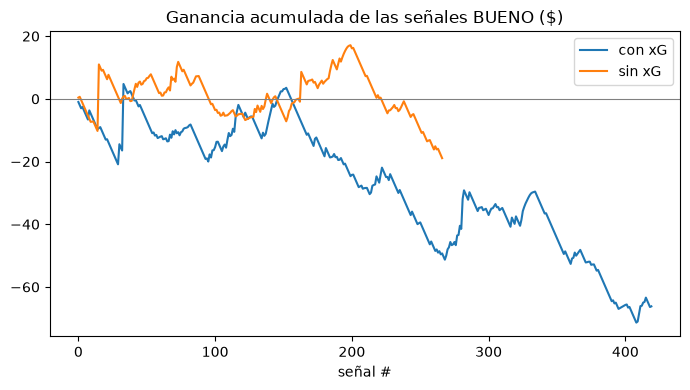

,con_xg,sin_xg
senales,420.000,267.000
aciertos,0.407,0.479
ganancia_por_dolar,-0.158,-0.071
ganancia_total,-66.186,-18.913


In [4]:
def ganancias(columna):
    salida = []
    for p in por_partido:
        previo = {}
        for f in p:
            if f[columna] == "BUENO" and previo.get(f["lado"]) != "BUENO" and f["compra"]:
                salida.append((f["t"], (1 / f["compra"] - 1) if f["gano"] else -1.0))
            previo[f["lado"]] = f[columna]
    return pd.Series([g for _, g in sorted(salida)])

fig, ax = plt.subplots(figsize=(7, 4))
for nombre, col in (("con xG", "senal_xg"), ("sin xG", "senal_sin")):
    ganancias(col).cumsum().reset_index(drop=True).plot(ax=ax, label=nombre)
ax.axhline(0, color="gray", lw=0.8); ax.set_title("Ganancia acumulada de las señales BUENO ($)")
ax.set_xlabel("señal #"); ax.legend(); plt.tight_layout()
plt.savefig(ROOT / "docs" / "backtest_senales.png", dpi=150); plt.show()
pd.DataFrame(resultados["senales"]).round(3)

## 4. ¿Es un problema del peso del xG?

El ritmo con xG mezcla el ritmo previo (pesa como W minutos) con el xG sin penales. Para no descartar el xG por
un mal peso, W se elige con los 40 partidos más antiguos y se evalúa en los 40 más recientes.

In [5]:
from src.live.xg_vivo import resumen_hasta

def brier_w(partidos, W):
    modelo.PESO_PREVIO_MIN = W or 60
    total, n = 0.0, 0
    for p in partidos:
        r = p["reloj"]
        previa = [bt._precio_en(p["precios"][l], r["kickoff"]) for l in bt.LADOS]
        lam = modelo.fit_lambdas(*previa)
        goles = [t for t in p["datos"]["tiros"] if t["gol"]]
        for t in bt._instantes(r):
            m = bt._minuto_juego(r, t)
            if round(m) not in bt.CORTES_BRIER:
                continue
            visto = t - bt.RETRASO_DATOS
            gl = sum(g["lado"] == "home" and g["instante"] <= visto for g in goles)
            gv = sum(g["lado"] == "away" and g["instante"] <= visto for g in goles)
            lv = modelo.ritmo_en_vivo(*lam, m, resumen_hasta(p["datos"], instante=visto)) if W else lam
            pr = modelo.live_probabilities(*lv, m, gl, gv)
            total += sum((pr[i] - (p["resultado"] == l)) ** 2 for i, l in enumerate(bt.LADOS))
            n += 1
    modelo.PESO_PREVIO_MIN = 60
    return total / n

desde = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=21)
partidos = []
for comp in bt.COMPETICIONES:
    for item in bt.eventos_cerrados(comp, desde.to_pydatetime()):
        if len(partidos) >= 80:
            break
        p = bt.preparar_partido(comp, item)
        if p:
            partidos.append(p)
partidos.sort(key=lambda p: p["inicio"])
mitad = len(partidos) // 2
pd.DataFrame(
    {"ajuste (40 más antiguos)": {W or "sin xG": brier_w(partidos[:mitad], W) for W in (None, 30, 60, 120, 240, 480, 960)},
     "prueba (40 más recientes)": {W or "sin xG": brier_w(partidos[mitad:], W) for W in (None, 30, 60, 120, 240, 480, 960)}}
).rename_axis("W (min)").round(4)

,ajuste (40 más antiguos),prueba (40 más recientes)
W (min),,
sin xG,0.3741,0.4809
30,0.3982,0.5364
60,0.3860,0.5143
120,0.3786,0.4992
240,0.3750,0.4903
480,0.3733,0.4856
960,0.3726,0.4832


## 5. Ruido del mercado: GARCH(1,1) contra varianza constante (QLIKE, menor es mejor)

In [6]:
pd.Series(resultados["garch"]).to_frame("valor")

,valor
qlike_garch,1025.352629
qlike_constante,610.355010
observaciones,8147.000000


## Conclusiones

- **El mercado de Polymarket pronosticó mejor que el modelo** en todos los minutos revisados (Brier más bajo).
  El modelo sin xG queda cerca del mercado porque arranca anclado a su precio.
- **El xG aproximado no ayudó a predecir:** empeoró el Brier y, fuera de muestra, entre más peso se le da peor
  pronostica. Con solo la zona del tiro (lo que publica ESPN), el precio ya incorpora lo que pasa en la cancha.
  Por eso la plataforma muestra el xG como información y calcula la señal sin él.
- **No hay adelanto:** la diferencia modelo − mercado casi no anticipa el movimiento del precio (correlación ~0.02).
- **Las señales BUENO perdieron dinero** una vez que se simula el atraso real (sin xG: −7¢ por $1; con xG: −16¢).
- **GARCH no superó a una varianza constante** para el ruido a 5 min; la plataforma usa en la práctica el
  mínimo de 2 pts.
- Limitaciones: 80 partidos de 5 ligas en 21 días; xG aproximado por zona; precio de compra estimado como
  último precio + 1 pt. Un xG con posición exacta del tiro podría cambiar la conclusión.